<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h1>The Model Building Framework</h1>
DAT-7470 - Business Analysis with Structured Data<br>
Script 04 - Completed Notebook<br><br>
Based on the course script by Chase Kusterer, Hult International Business School<br>
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

Our previous models had one major drawback:

<div align="center"><h4>The models were trained using all of the data.</h4></div>

If a model sees all of the data, it can <strong>overfit</strong>: it fits this dataset so closely that it predicts poorly on new observations. The goal of a model is to predict well on <em>new</em> cases, so we set aside some data before training (the <strong>testing</strong> or <strong>validation set</strong>). After training, the testing set shows how the model predicts on data it has never seen.

<strong>Some Things to Keep in Mind</strong>
1. Data exploration and feature engineering are always conducted on the full dataset.
2. Model adjustments should never be made on the testing set. The testing set is only used to check a model's fit.

<h4>Imports and Loading the Dataset</h4>
<strong>Google Colab:</strong> upload <code>diamonds.xlsx</code> with the folder icon on the left (Files &rarr; Upload), or run the cell below and pick the file when the upload button appears.

In [1]:
# importing packages
import pandas as pd                                  # data science essentials
import matplotlib.pyplot as plt                      # data viz
import seaborn as sns                                # enhanced data viz
import statsmodels.formula.api as smf                # linear modeling
from sklearn.model_selection import train_test_split # train/test split
import sklearn.linear_model                          # faster linear modeling
import numpy as np                                   # mathematical essentials
import os
import warnings

warnings.filterwarnings("ignore")                    # keeping the output clean


# specifying the path and file name (works in Google Colab and in local Jupyter)
file = None
for path in ["./diamonds.xlsx", "./datasets/diamonds.xlsx", "/content/diamonds.xlsx"]:
    if os.path.exists(path):
        file = path
        break

if file is None:                       # not found -> open Colab's upload button
    from google.colab import files
    uploaded = files.upload()          # choose diamonds.xlsx from your computer
    file = list(uploaded.keys())[0]


# converting data types with a dictionary
data_types = {"channel" : str,
              "store"   : str}


# reading the file into Python
diamonds = pd.read_excel(io      = file,
                         dtype   = data_types,
                         usecols = range(1, 8)) # omitting Obs


# checking the file
diamonds.head(n = 5)

,carat,color,clarity,cut,channel,store,price
0,0.32,3,7,0,0,7,1375
1,0.35,5,7,1,0,7,1680
2,0.40,4,7,1,0,7,2245
3,0.59,5,7,0,0,3,2495
4,0.72,7,8,0,0,8,2699


<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part I: Preparing Categorical Data</h2>
Categorical features must be turned into a series of yes/no (0/1) columns, more formally known as <strong>binary matrix factorization</strong> (one hot encoding). One category is then removed to avoid perfect collinearity (the <em>k-1</em> rule).
<em>Store</em> is left out on purpose, because many stores have too few diamonds for stable visualizations or models (see Script 02).<br><br>
Run the code below to instantiate the <em>categorical_boxplots</em> user-defined function.

In [2]:
# defining a function for categorical boxplots
def categorical_boxplots(response, cat_var, data):
    """
    This function generates a boxplot for a categorical variable.
    Make sure matplotlib.pyplot and seaborn have been imported (as plt and sns).

    PARAMETERS
    ----------
    response : str, response variable
    cat_var  : str, categorical variable
    data     : DataFrame of the response and categorical variables
    """

    fig, ax = plt.subplots(figsize = (10, 8))

    sns.boxplot(x    = response,
                y    = cat_var,
                data = data,
                order = sorted(data[cat_var].unique()))

    plt.suptitle("")
    plt.show()

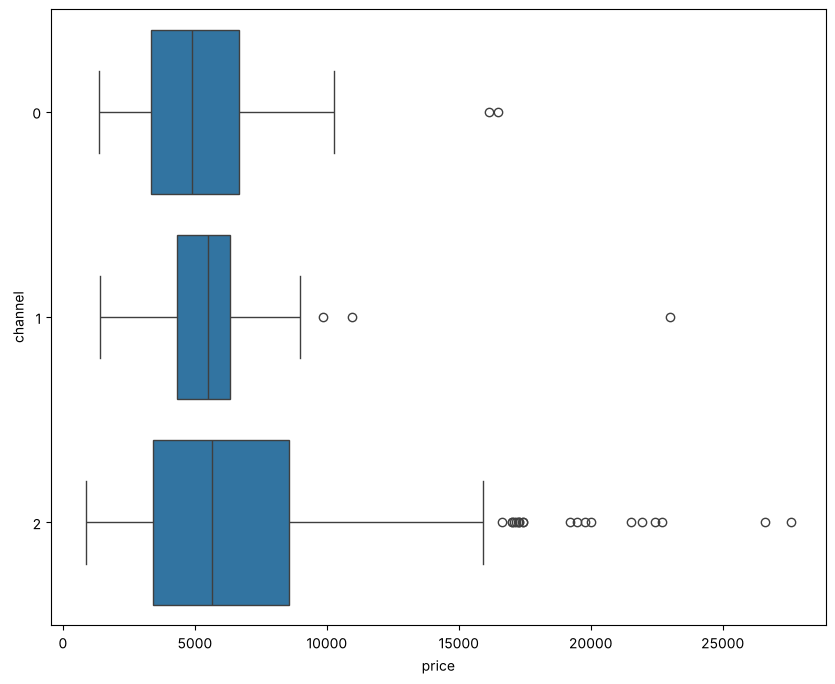

In [3]:
# calling the function for channel
categorical_boxplots(response = 'price',
                     cat_var  = 'channel',
                     data     = diamonds)

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<strong>a) Fill in the blanks in the code below to one hot encode <em>channel</em>.</strong>

In [4]:
help(pd.get_dummies)

Help on function get_dummies in module pandas:

get_dummies(
    data,
    prefix=None,
    prefix_sep: 'str | Iterable[str] | dict[str, str]' = '_',
    dummy_na: 'bool' = False,
    columns=None,
    sparse: 'bool' = False,
    drop_first: 'bool' = False,
    dtype: 'NpDtype | None' = None
) -> 'DataFrame'
    Convert categorical variable into dummy/indicator variables.

    Each variable is converted in as many 0/1 variables as there are different
    values. Columns in the output are each named after a value; if the input is
    a DataFrame, the name of the original variable is prepended to the value.

    Parameters
    ----------
    data : array-like, Series, or DataFrame
        Data of which to get dummy indicators.
    prefix : str, list of str, or dict of str, default None
        A string to be prepended to DataFrame column names.
        Pass a list with length equal to the number of columns
        when calling get_dummies on a DataFrame. Alternatively, `prefix`
        c

In [5]:
# one hot encoding categorical variables
one_hot_channel = pd.get_dummies(data   = diamonds['channel'],
                                 prefix = 'channel',
                                 dtype  = int)


# joining with rest of dataset
diamonds2 = diamonds.join([one_hot_channel])


# checking results
diamonds2.head(n = 5)

,carat,color,clarity,cut,channel,store,price,channel_0,channel_1,channel_2
0,0.32,3,7,0,0,7,1375,1,0,0
1,0.35,5,7,1,0,7,1680,1,0,0
2,0.40,4,7,1,0,7,2245,1,0,0
3,0.59,5,7,0,0,3,2495,1,0,0
4,0.72,7,8,0,0,8,2699,1,0,0


Each diamond now has a 1 in exactly one of the three new columns. We rename them with the channel names used in class.

In [6]:
# renaming channels (labels as given in the class script)
diamonds2.rename(columns = {'channel_0': 'mall',
                            'channel_1': 'independent',
                            'channel_2': 'internet'},
                 inplace = True)


# checking results
diamonds2.head(n = 5)

,carat,color,clarity,cut,channel,store,price,mall,independent,internet
0,0.32,3,7,0,0,7,1375,1,0,0
1,0.35,5,7,1,0,7,1680,1,0,0
2,0.40,4,7,1,0,7,2245,1,0,0
3,0.59,5,7,0,0,3,2495,1,0,0
4,0.72,7,8,0,0,8,2699,1,0,0


<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
Now we decide which category to drop to avoid the <strong>dummy variable trap</strong>. The three channel columns always add up to 1, so together they are perfectly collinear with the intercept, and OLS cannot be solved.

The dropped category becomes the <strong>baseline</strong> for interpretation. If we drop independent jewelers, the coefficients of the other channels are read as:

<div align="center"><h4>"Compared to independent jewelry stores, we can expect a price difference of <em>[coefficient value]</em> for diamonds being sold in <em>[channel]</em>."</h4></div>

A frequency table helps us choose.

In [7]:
# analyzing new feature counts
diamonds2[ ['mall', 'independent', 'internet'] ].sum()

mall            43
independent     48
internet       318
dtype: int64

<strong>Why drop independent?</strong> Dropping the largest group (internet, 318) is a common choice, but here independent jewelers make the most useful baseline for the business question: "how much more or less do I pay in a mall or online than at a traditional jeweler?" Independent and mall are also similar in size (48 and 43), so neither is a much better reference by sample size.

<strong>b) Complete the code below to drop independent jewelry stores from the dataset.</strong>
We also drop <em>channel</em> and <em>store</em>, as they are not suitable for predictive models in their current form.

In [8]:
# dropping features as needed
diamonds = diamonds2.drop(['independent', # category to drop
                           'channel',     # already factorized
                           'store',       # not enough samples per store
                          ], axis = 1)


# checking results
diamonds.head(n = 5)

,carat,color,clarity,cut,price,mall,internet
0,0.32,3,7,0,1375,1,0
1,0.35,5,7,1,1680,1,0
2,0.40,4,7,1,2245,1,0
3,0.59,5,7,0,2495,1,0
4,0.72,7,8,0,2699,1,0


<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part II: Training and Testing Sets</h2>
<h3>Organizing Data for Model Building</h3>
Before building models, we organize the x-data into feature sets. This lets us compare how different <strong>candidate models</strong> perform in predicting price.

In [9]:
## x-side ##
x_all  = diamonds.drop(labels = 'price', axis = 1)
x_base = diamonds[ ['carat', 'color', 'clarity', 'cut'] ]

## y-side ##
y_original = diamonds['price']

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
We select the feature sets for both the x- and y-sides. For now there is only one version of y.
<strong>a) Complete the code below using <em>x_all</em>.</strong>

In [10]:
# x-data
x_data = x_all

# y_data
y_data = y_original

# train-test split
x_train, x_test, y_train, y_test = train_test_split(x_data,
                                                    y_data,
                                                    test_size    = 0.35,
                                                    random_state = 702 )

In [11]:
# checking results
print(f"""
Data Shapes
-----------
x_train: {x_train.shape}
y_train: {y_train.shape}

x_test:  {x_test.shape}
y_test:  {y_test.shape}
""")


Data Shapes
-----------
x_train: (265, 6)
y_train: (265,)

x_test:  (144, 6)
y_test:  (144,)



65% of the 409 diamonds (265) are used for training and 35% (144) are held back for testing. Setting `random_state = 702` makes the random split the same every time, so the results can be reproduced.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part III: Linear Regression Modeling</h2>

* We always build on the training set.
* We never touch the testing set.

In [12]:
# naming the model
model_name = "Linear Regression"


# INSTANTIATING model object
model = sklearn.linear_model.LinearRegression()


# FITTING to training data
model_fit = model.fit(x_train, y_train)


# PREDICTING on new data
model_pred = model.predict(x_test)


# SCORING results (R-Square)
model_train_score = round(model.score(x_train, y_train), ndigits = 4)
model_test_score  = round(model.score(x_test, y_test), ndigits = 4)
model_gap         = round(model_train_score - model_test_score, ndigits = 4)


# displaying results
print('Training Score :', model_train_score)
print('Testing Score  :', model_test_score)
print('Train-Test Gap :', model_gap)

Training Score : 0.8949
Testing Score  : 0.8801
Train-Test Gap : 0.0148


<h3>Extracting Coefficients</h3>

In [13]:
# zipping each feature name to its coefficient
model_coefficients = zip(x_train.columns,
                         model.coef_.round(decimals = 4))


# setting up a placeholder list to store model features
coefficient_lst = [('intercept', model.intercept_.round(decimals = 4))]


# printing out each feature-coefficient pair one by one
for coefficient in model_coefficients:
    coefficient_lst.append(coefficient)


# checking the results
for pair in coefficient_lst:
    print(pair)

('intercept', np.float64(2407.399))
('carat', np.float64(10519.1169))
('color', np.float64(-665.5365))
('clarity', np.float64(-719.239))
('cut', np.float64(787.4504))
('mall', np.float64(947.8898))
('internet', np.float64(-1343.8102))


<h3>Model Summary</h3>

In [14]:
# dynamically printing model summary
ols_model =  f"""\
Model Name:     {model_name}
Train_Score:    {model_train_score}
Test_Score:     {model_test_score}
Train-Test Gap: {model_gap}

Coefficents
-----------
{pd.DataFrame(data = coefficient_lst, columns = ["Feature", "Coefficient"])}"""

print(ols_model)

Model Name:     Linear Regression
Train_Score:    0.8949
Test_Score:     0.8801
Train-Test Gap: 0.0148

Coefficents
-----------
     Feature  Coefficient
0  intercept    2407.3990
1      carat   10519.1169
2      color    -665.5365
3    clarity    -719.2390
4        cut     787.4504
5       mall     947.8898
6   internet   -1343.8102


<strong>Interpreting the full model:</strong>

* **Train 0.8949, Test 0.8801, Gap 0.0148.** The model explains about 88% of the price variation on diamonds it has **never seen**, and the gap is far below 0.05, so it is **not overfit**.
* **carat ≈ +\$10,519.** Each extra carat adds about \$10,500 to the price, holding everything else constant.
* **color ≈ -\$666 and clarity ≈ -\$719.** Each step down the color or clarity scale (a worse grade) lowers the price.
* **cut ≈ +\$788.** An Ideal cut adds about \$790.
* **mall ≈ +\$948.** Compared to independent jewelry stores, we can expect to pay about \$950 **more** in a mall.
* **internet ≈ -\$1,344.** Compared to independent jewelry stores, we can expect to pay about \$1,340 **less** online.
* **intercept ≈ \$2,407.** This is the baseline value of the line. It has no real meaning on its own, because no diamond has 0 carats.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<strong>How fit should a model be?</strong><br>
As a rule of thumb, if the training and testing scores are within 0.05 of each other, the model has not been overfit. A testing score higher than the training score is not a problem.

<h2>Exploring the Model Building Framework</h2>
Let's explore each component of the framework.

In [15]:
help(sklearn.linear_model.LinearRegression)

Help on class LinearRegression in module sklearn.linear_model._base:

class LinearRegression(sklearn.base.RegressorMixin, MultiOutputLinearModel)
 |  LinearRegression(
 |      *,
 |      fit_intercept=True,
 |      copy_X=True,
 |      tol=1e-06,
 |      n_jobs=None,
 |      positive=False
 |  )
 |
 |  Ordinary least squares Linear Regression.
 |
 |  LinearRegression fits a linear model with coefficients w = (w1, ..., wp)
 |  to minimize the residual sum of squares between the observed targets in
 |  the dataset, and the targets predicted by the linear approximation.
 |
 |  Parameters
 |  ----------
 |  fit_intercept : bool, default=True
 |      Whether to calculate the intercept for this model. If set
 |      to False, no intercept will be used in calculations
 |      (i.e. data is expected to be centered).
 |
 |  copy_X : bool, default=True
 |      If True, X will be copied; else, it may be overwritten.
 |
 |  tol : float, default=1e-6
 |      The precision of the solution (`coef_`) 

<h3>Instantiate</h3>Creates a blueprint of the model, just like with user-defined functions.

In [16]:
# this is a blueprint
model = sklearn.linear_model.LinearRegression()


# printing blueprint
print(model)

LinearRegression()


<h3>Fit</h3>Runs the data through the model, creating regression metrics such as R-Square and coefficients.

In [17]:
# model is created from blueprint and data
model_fit = model.fit(x_train, y_train)


# printing model attributes
print(f"""
Intercept
---------
{round(model_fit.intercept_, ndigits = 2)}


Coefficients
------------
{model_fit.coef_.round(decimals = 2)}


Total X-Features
----------------
{model_fit.n_features_in_}
""")


Intercept
---------
2407.4


Coefficients
------------
[10519.12  -665.54  -719.24   787.45   947.89 -1343.81]


Total X-Features
----------------
6



<h3>Predict</h3>Uses the fitted model to predict on the testing set. This shows how stable the model is on new data.

In [18]:
# applying model to validation set
model_pred = model.predict(x_test)


# printing predictions (validation set)
print(model_pred.round(decimals = 0).astype(dtype = int))

[-1320 11900  3772  3809  7473 12443  4747  6132  8583  6669  2562  5005
  5983 12771  4835  4828  2536  4923  7124  7709  4869  5006  2903  7971
 15232  3538  6456  9339 15389  7147 11915  6147  3957 10251   -55  4184
  9358 15300  1828  5483  7582  6428  7709  6794 10706  4835  5283  1833
  3886  7146  4554  5038  3553  4906  4272  5389  5743  4062 11900  2555
  3500  2781  6093  4921  -310  8299  3394 16021 11411  8972  7428  4832
 16653  6124  2592  3538  4219 10026 11357   255  -538  6303  6410 18559
  2272  4497   516  9602 13458 18613 12281 12964   941  -305  5254  5483
  1501  6640 15283  5377  2499  4789 10251   204  3183  7546 10706  6413
  4255  5511  2903  4423  7428  3644 15283  9916  1728  8007  1182   820
  3939 14141  5283  9390  8798  3888  4423  4624  2742  2306  1199  5743
  6904  7081  -811 10743  1662  5131  1626  5183  1063  1625  6303  4500]


In [19]:
## Residual Analysis ##

# organizing residuals
model_residuals = {
    "True"            : y_test,
    "Predicted"       : model_pred.round(decimals = 0).astype(dtype = int)
}


# converting residuals into df
resid_df = pd.DataFrame(data = model_residuals)


# checking results
resid_df.head(n = 5)

,True,Predicted
91,878,-1320
374,11910,11900
72,5895,3772
32,6685,3809
89,10950,7473


<strong>a)</strong> Complete the code to develop a residual plot from <em>resid_df</em>. Plot <em>Predicted</em> on the x-axis and <em>True</em> on the y-axis.

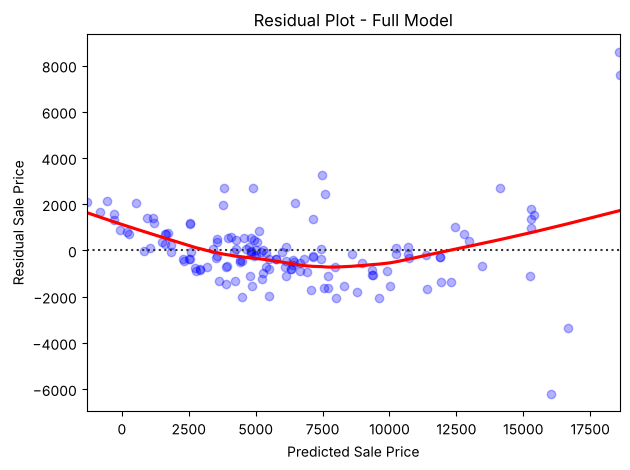

In [20]:
# developing a residual plot
sns.residplot(data        = resid_df,
              x           = 'Predicted',
              y           = 'True',
              lowess      = True,
              color       = 'blue',
              scatter_kws = {'alpha': 0.3},   # data point transparency
              line_kws    = {'color': 'red'}) # line color


# title and axis labels
plt.title(label   = "Residual Plot - Full Model")
plt.xlabel(xlabel = "Predicted Sale Price")
plt.ylabel(ylabel = "Residual Sale Price")


# layout and rendering visual
plt.tight_layout()
plt.show()

<strong>Reading the residual plot:</strong> each dot is one test diamond. Its height is the error (true price minus a straight-line fit of true on predicted). In a perfect model the dots would be scattered randomly around 0, and the red lowess line would be flat.

* The red lowess line is **not flat**. It has a **U-shape**: it is above 0 for cheap diamonds, below 0 in the middle (\$4,000 to \$11,000), and above 0 again for expensive diamonds.
* This means the model **under-predicts** both very cheap and very expensive diamonds, and **over-predicts** mid-priced ones. A straight line cannot follow the curved price–carat relationship we saw in Script 03.
* Some predictions for the smallest diamonds are **below \$0**, which is impossible. This is another sign that the straight line does not fit the low end.
* The few large errors (up to about +\$8,600 and -\$6,000) come from the most expensive diamonds, where there is very little data.

<h3>Score</h3>
Measures the quality of the predictions with a scoring metric (here, R-Square). More metrics <a href="https://scikit-learn.org/stable/modules/model_evaluation.html">can be found here</a>.

In [21]:
# checking overall predictive quality
print('Training Score:', round(model.score(x_train, y_train), ndigits = 4))
print('Testing  Score:', round(model.score(x_test, y_test),   ndigits = 4))
print('Train-Test Gap:', model_gap)

Training Score: 0.8949
Testing  Score: 0.8801
Train-Test Gap: 0.0148


<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part IV: Practice Time!</h2>
Run the framework again with different sets of x-data.

* Which feature set results in the highest R-Square value?
* Which one results in the lowest train-test gap?
* Are there any feature sets that flatten out the lowess estimator in the residual plot?

Instead of re-running the script by hand for each set, the function below runs the whole framework (split, instantiate, fit, predict, score) for one feature set. All sets use the same `test_size` and `random_state`, so the comparison is fair.

In [22]:
# a user-defined function for the full model building framework
def run_framework(x_data, y_data, name, plot = True):
    """
    Splits the data, fits a linear regression on the training set,
    scores it on both sets and (optionally) draws the residual plot.

    PARAMETERS
    ----------
    x_data : DataFrame, x-features
    y_data : Series, response variable
    name   : str, name of the feature set
    plot   : bool, draw the residual plot?
    """

    # train-test split (same settings as above)
    x_train, x_test, y_train, y_test = train_test_split(x_data,
                                                        y_data,
                                                        test_size    = 0.35,
                                                        random_state = 702 )

    # instantiate, fit, predict
    model      = sklearn.linear_model.LinearRegression()
    model_fit  = model.fit(x_train, y_train)
    model_pred = model.predict(x_test)

    # score
    train_score = round(model.score(x_train, y_train), ndigits = 4)
    test_score  = round(model.score(x_test,  y_test),  ndigits = 4)

    # residual plot
    if plot:
        resid_df = pd.DataFrame({"True"      : y_test,
                                 "Predicted" : model_pred.round(0)})

        sns.residplot(data        = resid_df,
                      x           = 'Predicted',
                      y           = 'True',
                      lowess      = True,
                      color       = 'blue',
                      scatter_kws = {'alpha': 0.3},
                      line_kws    = {'color': 'red'})

        plt.title(label   = f"Residual Plot - {name}")
        plt.xlabel(xlabel = "Predicted Sale Price")
        plt.ylabel(ylabel = "Residual Sale Price")
        plt.tight_layout()
        plt.show()

    return {"Feature Set"    : name,
            "Features"       : len(x_data.columns),
            "Training Score" : train_score,
            "Testing Score"  : test_score,
            "Train-Test Gap" : round(train_score - test_score, ndigits = 4)}

<strong>Candidate feature sets</strong>

| Name | Features | Why test it? |
|---|---|---|
| carat only | carat | the strongest single feature (correlation 0.88) |
| x_base | carat, color, clarity, cut | the four diamond characteristics |
| base + internet | x_base + internet | is the online discount enough, or is mall needed too? |
| x_all | x_base + mall + internet | the full model from Part III |
| x_all + carat² | x_all + carat squared | Script 03 showed that price rises faster than carat (a curve). Squaring carat lets a linear model bend |

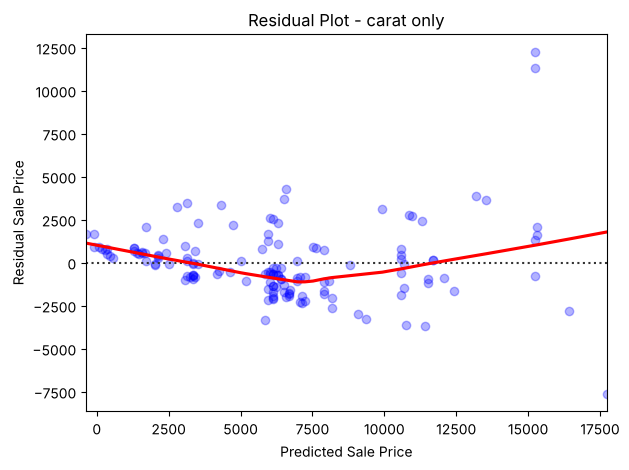

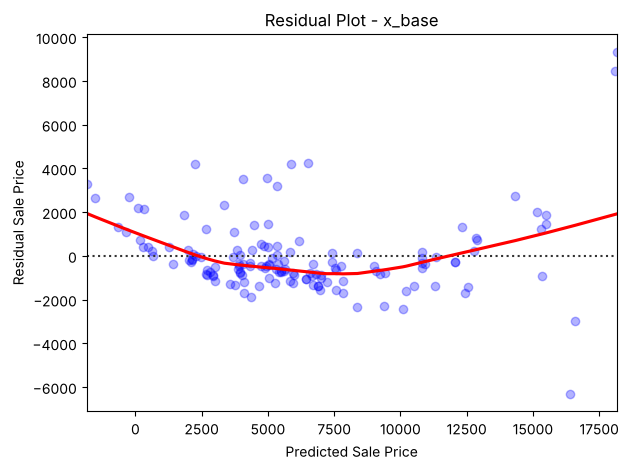

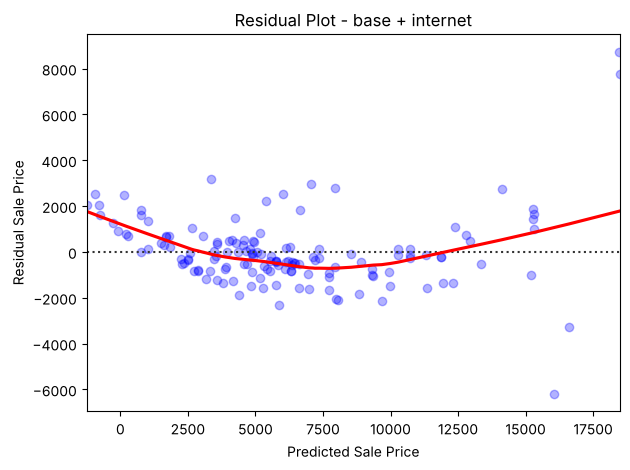

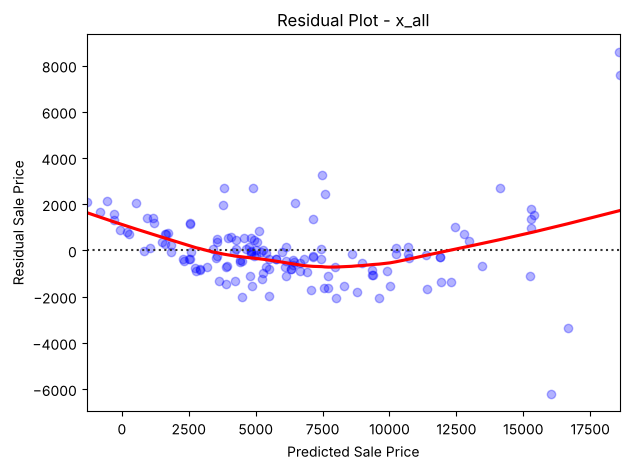

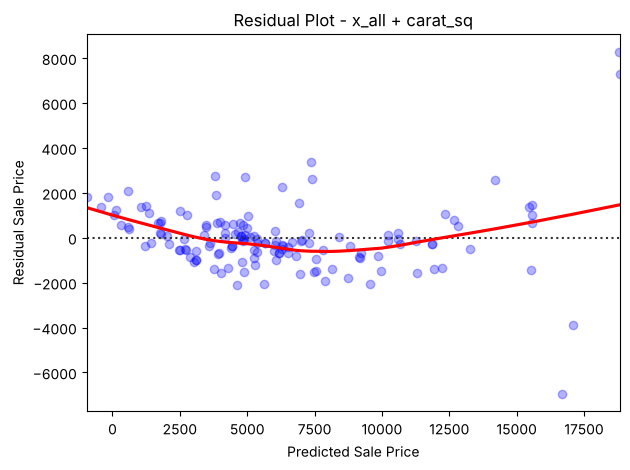

In [23]:
# feature engineering: squared carat to capture the curve seen in Script 03
diamonds['carat_sq'] = diamonds['carat'] ** 2


# candidate feature sets
feature_sets = {
    'carat only'       : diamonds[ ['carat'] ],
    'x_base'           : x_base,
    'base + internet'  : diamonds[ ['carat', 'color', 'clarity', 'cut', 'internet'] ],
    'x_all'            : x_all,
    'x_all + carat_sq' : diamonds[ ['carat', 'carat_sq', 'color', 'clarity', 'cut', 'mall', 'internet'] ]
}


# running the framework for each feature set
model_results = []

for name, x_set in feature_sets.items():
    model_results.append( run_framework(x_data = x_set,
                                        y_data = y_original,
                                        name   = name) )

In [24]:
# comparing all candidate models
comparison = pd.DataFrame(model_results)
comparison.sort_values(by = 'Testing Score', ascending = False)

,Feature Set,Features,Training Score,Testing Score,Train-Test Gap
4,x_all + carat_sq,7,0.8964,0.8821,0.0143
3,x_all,6,0.8949,0.8801,0.0148
2,base + internet,5,0.8923,0.8742,0.0181
1,x_base,4,0.8706,0.8422,0.0284
0,carat only,1,0.7809,0.7579,0.0230


<strong>Answers</strong>

* **Highest R-Square:** **x_all + carat²** (test 0.8821), just ahead of **x_all** (test 0.8801). Adding the channel dummies gives the biggest improvement: about +0.04 on the test score compared with x_base. Adding only *internet* already captures most of this gain (0.8742).
* **Lowest train-test gap:** again **x_all + carat²** (0.0143), with **x_all** close behind (0.0148). All five feature sets have gaps well under 0.05, so **none of them is overfit**. Adding features did not hurt stability here.
* **Flattening the lowess line:** **no feature set fully flattens it.** Every residual plot keeps the U-shape. *carat²* makes the U slightly shallower, but the improvement is small (+0.002 on the test score). The curve comes from the **y-side**: price is strongly right-skewed (Script 03), and its spread grows with its size. The usual fix is to transform price itself (for example, taking its logarithm), which will be covered as we advance with different versions of y.

<strong>Choice:</strong> **x_all** is the best model to carry forward. It is almost as accurate as *x_all + carat²* with one feature fewer and easier coefficients to explain. Following the principle of keeping a model simple when the gain from complexity is small, x_all is the better business model.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" /><hr style="height:.9px;border:none;color:#333;background-color:#333;" />

~~~
  _    _                           __  __           _      _ _             _
 | |  | |                         |  \/  |         | |    | (_)           | |
 | |__| | __ _ _ __  _ __  _   _  | \  / | ___   __| | ___| |_ _ __   __ _| |
 |  __  |/ _` | '_ \| '_ \| | | | | |\/| |/ _ \ / _` |/ _ \ | | '_ \ / _` | |
 | |  | | (_| | |_) | |_) | |_| | | |  | | (_) | (_| |  __/ | | | | | (_| |_|
 |_|  |_|\__,_| .__/| .__/ \__, | |_|  |_|\___/ \__,_|\___|_|_|_| |_|\__, (_)
              | |   | |     __/ |                                     __/ |
              |_|   |_|    |___/                                     |___/
~~~
<hr style="height:.9px;border:none;color:#333;background-color:#333;" /><hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h2>Bonus I: Using Statsmodels for p-values</h2>
scikit-learn does not give p-values, but statsmodels does. The model below uses the full dataset with the same features as <em>x_all</em>.

In [25]:
# Step 1: INSTANTIATE a model object
lm = smf.ols(formula =  """price ~ carat   +
                                   color   +
                                   clarity +
                                   cut     +
                                   mall    +
                                   internet""",
            data = diamonds)


# Step 2: FIT the data into the model object
results = lm.fit()


# Step 3: analyze the SUMMARY output
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.891
Model:                            OLS   Adj. R-squared:                  0.890
Method:                 Least Squares   F-statistic:                     549.3
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          3.18e-190
Time:                        16:20:02   Log-Likelihood:                -3558.6
No. Observations:                 409   AIC:                             7131.
Df Residuals:                     402   BIC:                             7159.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   2419.3909    435.931      5.550      0.0

<strong>Reading the output:</strong>

* **All features are significant** (every p-value is 0.000), and adjusted R-squared is **0.890**.
* The coefficients are close to the scikit-learn ones, but not identical. statsmodels here uses **all 409 diamonds**, while scikit-learn used only the training set (265 diamonds).
* **mall = +\$1,234 and internet = -\$1,402**, both compared to independent jewelry stores. These are the same channel effects as Model 2 in Script 03, just measured from a different baseline. This confirms that the choice of which category to drop changes the *interpretation*, but not the model's predictions.
* **Durbin-Watson = 1.08** (below 2) and **Jarque-Bera** is very large. The errors are not normally distributed and follow a pattern, which matches the U-shape in the residual plot.

<h2>Bonus II: Saving the Dataset to Excel</h2>
The <em>to_excel()</em> method saves a DataFrame as an Excel file.

In [26]:
help(diamonds.to_excel)

Help on method to_excel in module pandas.core.generic:

to_excel(
    excel_writer: 'FilePath | WriteExcelBuffer | ExcelWriter',
    *,
    sheet_name: 'str' = 'Sheet1',
    na_rep: 'str' = '',
    float_format: 'str | None' = None,
    columns: 'Sequence[Hashable] | None' = None,
    header: 'Sequence[Hashable] | bool' = True,
    index: 'bool' = True,
    index_label: 'IndexLabel | None' = None,
    startrow: 'int' = 0,
    startcol: 'int' = 0,
    engine: "Literal['openpyxl', 'xlsxwriter'] | None" = None,
    merge_cells: 'bool' = True,
    inf_rep: 'str' = 'inf',
    freeze_panes: 'tuple[int, int] | None' = None,
    storage_options: 'StorageOptions | None' = None,
    engine_kwargs: 'dict[str, Any] | None' = None,
    autofilter: 'bool' = False
) -> 'None' method of pandas.DataFrame instance
    Write object to an Excel sheet.

    To write a single object to an Excel .xlsx file it is only necessary to
    specify a target file name. To write to multiple sheets it is necessary to


In [27]:
# making sure the datasets folder exists (Colab starts without it)
os.makedirs('./datasets', exist_ok = True)


# storing the dataset as an Excel file (without the engineered carat_sq column)
diamonds.drop(labels = 'carat_sq', axis = 1)\
        .to_excel(excel_writer = './datasets/diamonds_prepped.xlsx',
                  index        = False)


# checking that the file was saved
pd.read_excel('./datasets/diamonds_prepped.xlsx').head(n = 5)

,carat,color,clarity,cut,price,mall,internet
0,0.32,3,7,0,1375,1,0
1,0.35,5,7,1,1680,1,0
2,0.40,4,7,1,2245,1,0
3,0.59,5,7,0,2495,1,0
4,0.72,7,8,0,2699,1,0


In Colab the file is saved in the <code>datasets</code> folder in the file panel on the left. Right-click it and choose <strong>Download</strong> to keep a copy, because Colab deletes files when the session ends.